In [60]:
#Importing the libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import (
    LinearRegression, Ridge, Lasso, ElasticNet
)
from sklearn.metrics import r2_score, mean_squared_error

In [61]:
# import the dataset
data = pd.read_csv('StudentsPerformance.csv')

In [62]:
data.head()

,gender,race/ethnicity,test preparation course,math score,reading score,writing score
0,female,group B,none,72,72,74
1,female,group C,completed,69,90,88
2,female,group B,none,90,95,93
3,male,group A,none,47,57,44
4,male,group C,none,76,78,75


In [63]:
data

,gender,race/ethnicity,test preparation course,math score,reading score,writing score
0,female,group B,none,72,72,74
1,female,group C,completed,69,90,88
2,female,group B,none,90,95,93
3,male,group A,none,47,57,44
4,male,group C,none,76,78,75
...,...,...,...,...,...,...
995,female,group E,completed,88,99,95
996,male,group C,none,62,55,55
997,female,group C,completed,59,71,65
998,female,group D,completed,68,78,77


In [64]:
#MEASURE OF CENTRAL TENDENCY

In [65]:
# find the average of each numerical column
data.mean(numeric_only=True)

math score       66.089
reading score    69.169
writing score    68.054
dtype: float64

In [66]:
# find the average marks of Math
data['math score'].mean()

np.float64(66.089)

In [67]:
# find the middle mark of Math
data['math score'].median()

np.float64(66.0)

In [68]:
# find the mode of Math marks
data['math score'].mode()[0]

np.int64(65)

In [69]:
#MEASURE OF DISPERSION

In [70]:
# find the minimum marks scored in Math
data['math score'].min()

np.int64(0)

In [71]:
# find the maximum marks scored in Math
data['math score'].max()

np.int64(100)

In [72]:
# find the range of marks scored in Math
data['math score'].max() - data['math score'].min()

np.int64(100)

In [73]:
# find how Math marks are deviated from the average
data['math score'].std()

np.float64(15.16308009600945)

In [74]:
# find the variance of Math marks
data['math score'].var()

np.float64(229.91899799799796)

In [75]:
#MEASURE OF POSITION

In [76]:
# check the skewness of Math marks
data['math score'].skew()

np.float64(-0.27893514909431694)

In [77]:
# check the kurtosis of Math marks
data['math score'].kurt()

np.float64(0.27496405752108455)

In [78]:
# find the different quantiles for Math marks
print(
    data['math score'].quantile(0),
    data['math score'].quantile(0.25),
    data['math score'].quantile(0.50),
    data['math score'].quantile(0.75),
    data['math score'].quantile(1)
)

0.0 57.0 66.0 77.0 100.0


In [79]:
# find the inter quartile range (IQR) for Math marks
data['math score'].quantile(0.75) - data['math score'].quantile(0.25)

np.float64(20.0)

In [80]:
def descriptive_stats(sample, field):
    return sample[field].describe()

In [81]:
# Generate 150 random samples of the data
sample = data.sample(150)

sample

,gender,race/ethnicity,test preparation course,math score,reading score,writing score
869,male,group C,none,49,51,51
0,female,group B,none,72,72,74
229,female,group C,completed,88,95,94
979,female,group C,none,91,95,94
469,male,group C,none,91,74,76
...,...,...,...,...,...,...
714,female,group B,completed,60,70,74
550,male,group C,none,79,76,65
101,male,group D,completed,68,74,74
894,female,group E,none,59,62,69


In [82]:
# Display the descriptive statistics for the random sample
descriptive_stats(sample, 'math score')

count    150.000000
mean      65.333333
std       16.154317
min        8.000000
25%       54.250000
50%       65.000000
75%       77.000000
max      100.000000
Name: math score, dtype: float64

In [83]:
# Create a program to random sampling of size 150 
sample = data.sample(150)

sample

,gender,race/ethnicity,test preparation course,math score,reading score,writing score
328,male,group C,completed,82,75,77
937,female,group E,none,57,58,57
154,male,group D,none,62,67,61
57,male,group D,none,52,55,49
639,female,group D,none,76,74,73
...,...,...,...,...,...,...
463,female,group C,none,77,90,91
53,male,group D,none,88,78,75
942,male,group C,none,81,66,64
92,male,group C,none,71,79,71


In [84]:
descriptive_stats(sample, 'math score')

count    150.000000
mean      68.513333
std       14.462976
min       33.000000
25%       59.000000
50%       69.000000
75%       79.000000
max      100.000000
Name: math score, dtype: float64

In [85]:
# Create systematic sampling

interval = 7

systematic_sample = data.iloc[::interval]

systematic_sample = systematic_sample.head(150)

systematic_sample

,gender,race/ethnicity,test preparation course,math score,reading score,writing score
0,female,group B,none,72,72,74
7,male,group B,none,40,43,39
14,female,group A,none,50,53,58
21,female,group B,completed,65,75,70
28,male,group C,none,70,70,65
...,...,...,...,...,...,...
966,male,group A,completed,66,68,64
973,female,group D,none,49,65,61
980,female,group B,none,8,24,23
987,male,group E,completed,81,75,76


In [86]:
# Create a systematic sample by extracting every 5th row

systematic_sample = data.iloc[::5]

systematic_sample

,gender,race/ethnicity,test preparation course,math score,reading score,writing score
0,female,group B,none,72,72,74
5,female,group B,none,71,83,78
10,male,group C,none,58,54,52
15,female,group C,none,69,75,78
20,male,group D,none,66,69,63
...,...,...,...,...,...,...
975,female,group C,completed,64,82,77
980,female,group B,none,8,24,23
985,male,group A,none,57,51,54
990,male,group E,completed,86,81,75


In [87]:
# Display the descriptive statistics for the systematic sample

descriptive_stats(systematic_sample, 'math score')

count    200.000000
mean      67.035000
std       14.699803
min        8.000000
25%       58.000000
50%       68.000000
75%       77.250000
max      100.000000
Name: math score, dtype: float64

In [88]:
descriptive_stats(data, 'math score')

count    1000.00000
mean       66.08900
std        15.16308
min         0.00000
25%        57.00000
50%        66.00000
75%        77.00000
max       100.00000
Name: math score, dtype: float64

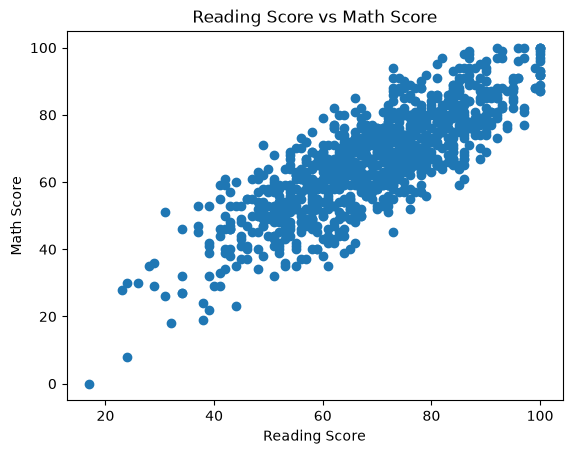

In [89]:
#Scatter Plot
plt.scatter(data["reading score"], data["math score"])

plt.xlabel("Reading Score")
plt.ylabel("Math Score")
plt.title("Reading Score vs Math Score")

plt.show()

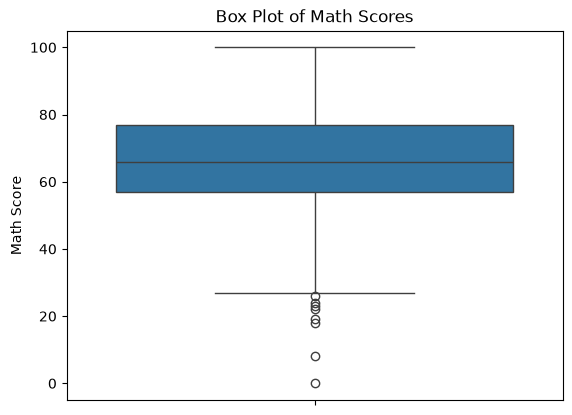

In [90]:
#Box Plot 
sns.boxplot(y=data["math score"])

plt.ylabel("Math Score")
plt.title("Box Plot of Math Scores")

plt.show()

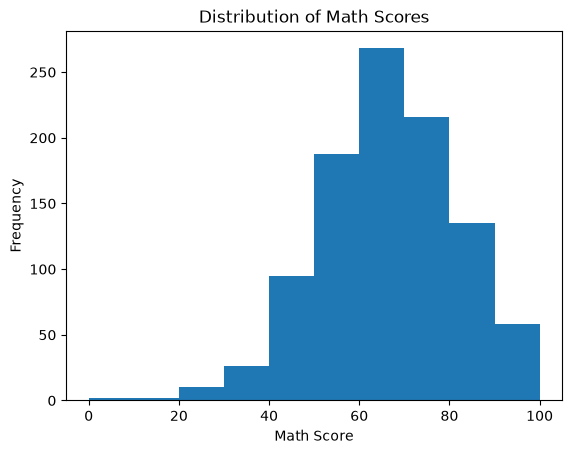

In [91]:
# Histogram 
plt.hist(data["math score"], bins=10)

plt.xlabel("Math Score")
plt.ylabel("Frequency")
plt.title("Distribution of Math Scores")

plt.show()

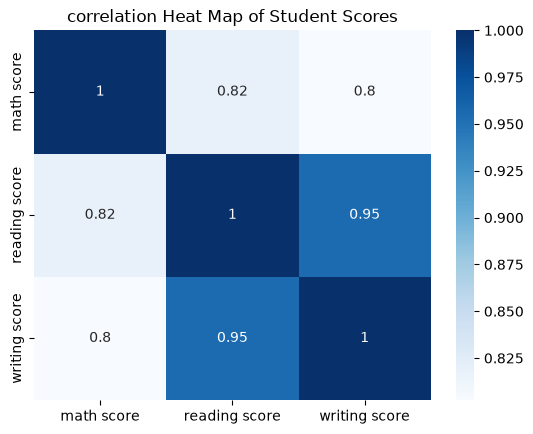

In [92]:
# Heat Map
scores = data[["math score", "reading score", "writing score"]]

correlation = scores.corr()

sns.heatmap(correlation, annot=True, cmap="Blues")

plt.title("correlation Heat Map of Student Scores")
plt.show()

In [93]:
# Pearson Correlation 
from scipy.stats import pearsonr

pearson_r, p_value = pearsonr(
    data["reading score"],
    data["math score"]
)

print("Pearson Correlation: ", pearson_r)
print("P-value: ", p_value)


Pearson Correlation:  0.8175796636720541
P-value:  1.787753109906147e-241


In [94]:
# Spearman Correlation 
from scipy.stats import spearmanr

spearman_r, p_value = spearmanr(
    data["reading score"],
    data["math score"]
)

print("Spearman Correlation:", spearman_r)
print("P-value:", p_value)

Spearman Correlation: 0.8040638885551746
P-value: 1.3538514946749083e-227


In [95]:
#One Sample T-test 
from scipy.stats import ttest_1samp

population_mean = data["math score"].mean()
sample = data["math score"].sample(n=150, random_state=42)
sample_mean = sample.mean()

t_stat, p_value = ttest_1samp(sample, population_mean)

print("Population Mean:", population_mean)
print("Sample Mean:", sample_mean)
print("T-statistic:", t_stat)
print("P-value:", p_value)

Population Mean: 66.089
Sample Mean: 63.693333333333335
T-statistic: -1.8069069272025697
P-value: 0.07279448145178259


In [96]:
# D2

In [97]:
# Data Cleaning: checking missing values and duplicates
print("Missing Values:")
print(data.isnull().sum())
print("Duplicate Rows:", data.duplicated().sum())

Missing Values:
gender                     0
race/ethnicity             0
test preparation course    0
math score                 0
reading score              0
writing score              0
dtype: int64
Duplicate Rows: 2


In [98]:
# Select independent and dependent variables
x = data.iloc[:, [4, 5]].values
y = data.iloc[:, 3].values
print("Independent Variables (Reading and Writing):")
print(x[:5])
print("Dependent Variable (Math):")
print(y[:5])


Independent Variables (Reading and Writing):
[[72 74]
 [90 88]
 [95 93]
 [57 44]
 [78 75]]
Dependent Variable (Math):
[72 69 90 47 76]


In [99]:
# Splitting the dataset into Training and Test sets
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size = 0.2, random_state = 0
)
print("Training Records:", len(x_train))
print("Testing Records:", len(x_test))

Training Records: 800
Testing Records: 200


In [100]:
# Detecting and removing outliers using IQR (training data only)
import numpy as np
mask = np.ones(len(x_train), dtype=bool)
for i in range(x_train.shape[1]):
    Q1 = np.percentile(x_train[:, i], 25)
    Q3 = np.percentile(x_train[:, i], 75)
    IQR = Q3 - Q1
    mask = mask & (x_train[:, i] >= Q1 - 1.5 * IQR) & (x_train[:, i] <= Q3 + 1.5 * IQR)
print("Training outliers removed:", len(x_train) - mask.sum())
x_train = x_train[mask]
y_train = y_train[mask]

Training outliers removed: 4


In [101]:
#FUTURE SCAILING
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
x_train = sc.fit_transform(x_train)
x_test = sc.transform(x_test)

In [102]:
# Simple Linear Regression
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
# Select Reading Score as the independent variable
X = data[['reading score']]
y = data['math score']
# Split the dataset into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
# Train the model
simple_reg = LinearRegression()
simple_reg.fit(X_train, y_train)
# Predict test results
y_pred_simple = simple_reg.predict(X_test)
# Evaluate performance
print("Simple Linear Regression R2:", r2_score(y_test, y_pred_simple))
print("Simple Linear Regression MSE:", mean_squared_error(y_test, y_pred_simple))
# Display regression equation components
print("Intercept:", simple_reg.intercept_)
print("Coefficient:", simple_reg.coef_[0])


Simple Linear Regression R2: 0.6804469009921285
Simple Linear Regression MSE: 77.75953982761705
Intercept: 7.61591514772217
Coefficient: 0.8465291474700284


In [103]:
# Multiple Linear Regression
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
import pandas as pd
# Select all independent variables
X_mlr = data.drop(columns=['math score'])
y_mlr = data['math score']
# Encode categorical variables
X_mlr = pd.get_dummies(X_mlr, drop_first=True, dtype=int)
# Split into 80% training and 20% testing
X_train_mlr, X_test_mlr, y_train_mlr, y_test_mlr = train_test_split(
    X_mlr, y_mlr, test_size=0.2, random_state=42
)
# Train the Multiple Linear Regression model
multiple_reg = LinearRegression()
multiple_reg.fit(X_train_mlr, y_train_mlr)
# Predict test results
y_pred_mlr = multiple_reg.predict(X_test_mlr)
# Evaluate performance
print("Multiple Linear Regression R2:",
      r2_score(y_test_mlr, y_pred_mlr))

print("Multiple Linear Regression MSE:",
      mean_squared_error(y_test_mlr, y_pred_mlr))
# Display regression equation components
print("Intercept:", multiple_reg.intercept_)
print("Coefficients:")
print(pd.Series(multiple_reg.coef_, index=X_mlr.columns))


Multiple Linear Regression R2: 0.8773810099577825
Multiple Linear Regression MSE: 29.83790884648914
Intercept: -10.63875937983714
Coefficients:
reading score                    0.219389
writing score                    0.768455
gender_male                     13.490651
race/ethnicity_group B           0.461386
race/ethnicity_group C          -0.589372
race/ethnicity_group D          -0.758581
race/ethnicity_group E           4.864129
test preparation course_none     3.789979
dtype: float64


In [104]:
# Polynomial Regression (Degree 2)
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
# Create polynomial features of degree 2
poly = PolynomialFeatures(degree=2, include_bias=False)
# Transform training and testing data
X_train_poly = poly.fit_transform(X_train_mlr)
X_test_poly = poly.transform(X_test_mlr)
# Train Polynomial Regression model
poly_reg = LinearRegression()
poly_reg.fit(X_train_poly, y_train_mlr)
# Predict test results
y_pred_poly = poly_reg.predict(X_test_poly)
# Evaluate performance
print("Polynomial Regression R2:",
      r2_score(y_test_mlr, y_pred_poly))

print("Polynomial Regression MSE:",
      mean_squared_error(y_test_mlr, y_pred_poly))
# Display regression equation components
print("Intercept:", poly_reg.intercept_)
print("Number of coefficients:", len(poly_reg.coef_))


Polynomial Regression R2: 0.8755939779820894
Polynomial Regression MSE: 30.27276234820313
Intercept: 0.7573284234028677
Number of coefficients: 44


In [105]:
# Ridge Regression
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error
# Standardize the independent variables
scaler_ridge = StandardScaler()
X_train_ridge = scaler_ridge.fit_transform(X_train_mlr)
X_test_ridge = scaler_ridge.transform(X_test_mlr)
# Train Ridge Regression model
ridge_reg = Ridge(alpha=1.0)
ridge_reg.fit(X_train_ridge, y_train_mlr)
# Predict test results
y_pred_ridge = ridge_reg.predict(X_test_ridge)
# Evaluate performance
print("Ridge Regression R2:",
      r2_score(y_test_mlr, y_pred_ridge))

print("Ridge Regression MSE:",
      mean_squared_error(y_test_mlr, y_pred_ridge))
# Display regression equation components
print("Intercept:", ridge_reg.intercept_)
print("Coefficients:", ridge_reg.coef_)


Ridge Regression R2: 0.8776455075804289
Ridge Regression MSE: 29.773546418190552
Intercept: 66.49625
Coefficients: [ 3.31017367 11.42300403  6.71241585  0.17991834 -0.27378772 -0.31987891
  1.71079123  1.78604324]


In [106]:
# Lasso Regression
from sklearn.linear_model import Lasso
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error
# Standardize the independent variables
scaler_lasso = StandardScaler()
X_train_lasso = scaler_lasso.fit_transform(X_train_mlr)
X_test_lasso = scaler_lasso.transform(X_test_mlr)
# Train Lasso Regression model
lasso_reg = Lasso(alpha=1.0, max_iter=10000)
lasso_reg.fit(X_train_lasso, y_train_mlr)
# Predict test results
y_pred_lasso = lasso_reg.predict(X_test_lasso)
# Evaluate performance
print("Lasso Regression R2:",
      r2_score(y_test_mlr, y_pred_lasso))

print("Lasso Regression MSE:",
      mean_squared_error(y_test_mlr, y_pred_lasso))
# Display regression equation components
print("Intercept:", lasso_reg.intercept_)
print("Coefficients:", lasso_reg.coef_)

Lasso Regression R2: 0.8498094046073918
Lasso Regression MSE: 36.547139177884645
Intercept: 66.49625
Coefficients: [ 5.10603241  7.64783223  4.99237925 -0.         -0.         -0.
  0.85405843  0.        ]


In [107]:
# Elastic Net Regression
from sklearn.linear_model import ElasticNet
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error
# Standardize the independent variables
scaler_elastic = StandardScaler()
X_train_elastic = scaler_elastic.fit_transform(X_train_mlr)
X_test_elastic = scaler_elastic.transform(X_test_mlr)
# Train Elastic Net Regression model
elastic_reg = ElasticNet(alpha=1.0, l1_ratio=0.5, max_iter=10000)
elastic_reg.fit(X_train_elastic, y_train_mlr)
# Predict test results
y_pred_elastic = elastic_reg.predict(X_test_elastic)
# Evaluate performance
print("Elastic Net Regression R2:",
      r2_score(y_test_mlr, y_pred_elastic))

print("Elastic Net Regression MSE:",
      mean_squared_error(y_test_mlr, y_pred_elastic))
# Display regression equation components
print("Intercept:", elastic_reg.intercept_)
print("Coefficients:", elastic_reg.coef_)


Elastic Net Regression R2: 0.7729284405476472
Elastic Net Regression MSE: 55.255229962640406
Intercept: 66.49625
Coefficients: [ 5.04233478  5.0652385   3.10748109 -0.         -0.08930613  0.
  1.06593876  0.        ]


In [108]:
# Regression Model Performance Comparison
import pandas as pd
from sklearn.metrics import r2_score, mean_squared_error
# Compare all six regression models
comparison = pd.DataFrame({
    'Regression Model': [
        'Simple Linear Regression',
        'Multiple Linear Regression',
        'Polynomial Regression',
        'Ridge Regression',
        'Lasso Regression',
        'Elastic Net Regression'
    ],
    'R2': [
        r2_score(y_test, y_pred_simple),
        r2_score(y_test_mlr, y_pred_mlr),
        r2_score(y_test_mlr, y_pred_poly),
        r2_score(y_test_mlr, y_pred_ridge),
        r2_score(y_test_mlr, y_pred_lasso),
        r2_score(y_test_mlr, y_pred_elastic)
    ],
    'MSE': [
        mean_squared_error(y_test, y_pred_simple),
        mean_squared_error(y_test_mlr, y_pred_mlr),
        mean_squared_error(y_test_mlr, y_pred_poly),
        mean_squared_error(y_test_mlr, y_pred_ridge),
        mean_squared_error(y_test_mlr, y_pred_lasso),
        mean_squared_error(y_test_mlr, y_pred_elastic)
    ]
})
# Display the comparison table
print(comparison.round(4).to_string(index=False))


          Regression Model     R2     MSE
  Simple Linear Regression 0.6804 77.7595
Multiple Linear Regression 0.8774 29.8379
     Polynomial Regression 0.8756 30.2728
          Ridge Regression 0.8776 29.7735
          Lasso Regression 0.8498 36.5471
    Elastic Net Regression 0.7729 55.2552


In [109]:
# Best-Fit Regression Model Selection
# Select the model with the highest R2 score
best_model = comparison.loc[comparison['R2'].idxmax()]
# Display the best-fitting model
print("Best-Fit Regression Model:", best_model['Regression Model'])
print("R2 Score:", round(best_model['R2'], 4))
print("MSE:", round(best_model['MSE'], 4))


Best-Fit Regression Model: Ridge Regression
R2 Score: 0.8776
MSE: 29.7735


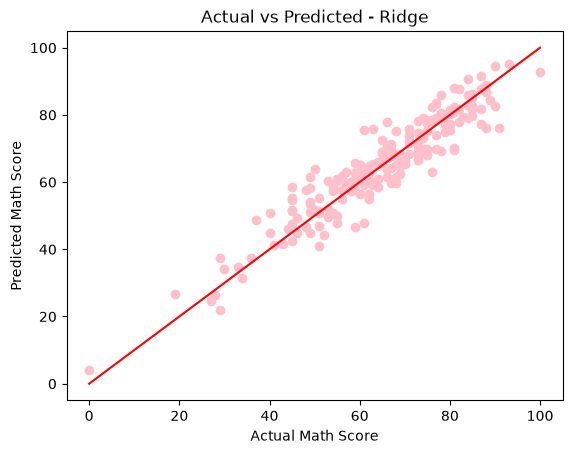

In [110]:
# Visualizing the Best Regression Model

best_name = 'Ridge'

if best_name == 'Polynomial':
    y_pred_best = y_pred_poly
elif best_name == 'Multiple Linear':
    y_pred_best = y_pred
elif best_name == 'Ridge':
    y_pred_best = y_pred_ridge
elif best_name == 'Lasso':
    y_pred_best = y_pred_lasso
else:
    y_pred_best = y_pred_elastic

plt.scatter(y_test, y_pred_best, color='pink')
plt.plot([0, 100], [0, 100], color='red')

plt.title('Actual vs Predicted - ' + best_name)
plt.xlabel('Actual Math Score')
plt.ylabel('Predicted Math Score')
plt.show()



In [111]:
#Naive Bayes - P1
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Creating Pass/Fail Categories
data['Math_Result'] = data['math score'].apply(
    lambda score: 'Pass' if score >= 50 else 'Fail'
)

# Independent and Dependent Variables
X = data[['reading score', 'writing score']]
y = data['Math_Result']

# Splitting the Dataset
X_train_class, X_test_class, y_train_class, y_test_class = train_test_split(
    X, y, test_size=0.2, random_state=0, stratify=y
)

# Feature Scaling
sc = StandardScaler()
X_train_scaled = sc.fit_transform(X_train_class)
X_test_scaled = sc.transform(X_test_class)

print(data['Math_Result'].value_counts())


Math_Result
Pass    865
Fail    135
Name: count, dtype: int64


In [112]:
# Naive Bayes - P2
from sklearn.naive_bayes import GaussianNB

# Training the Model
classifier = GaussianNB()
classifier.fit(X_train_scaled, y_train_class)

# Predicting the Test Set
y_pred_nb = classifier.predict(X_test_scaled)

In [113]:
# Naive Bayes - P3
from sklearn.metrics import confusion_matrix, accuracy_score
from sklearn.metrics import precision_score, recall_score, f1_score

# Making the Confusion Matrix
cm = confusion_matrix(y_test_class, y_pred_nb,
                      labels=['Fail', 'Pass'])
print("Confusion Matrix:")
print(cm)

# Evaluating the Model
print("Accuracy:", accuracy_score(y_test_class, y_pred_nb))
print("Precision:", precision_score(y_test_class, y_pred_nb, pos_label='Fail'))
print("Recall:", recall_score(y_test_class, y_pred_nb, pos_label='Fail'))
print("F1-score:", f1_score(y_test_class, y_pred_nb, pos_label='Fail'))

Confusion Matrix:
[[ 21   6]
 [ 13 160]]
Accuracy: 0.905
Precision: 0.6176470588235294
Recall: 0.7777777777777778
F1-score: 0.6885245901639344


In [114]:
predicted_counts = pd.Series(y_pred_nb).value_counts()
print("Naïve Bayes - Predicted Categories:")
print(predicted_counts)

Naïve Bayes - Predicted Categories:
Pass    166
Fail     34
Name: count, dtype: int64
